# Лабораторная работа №6. Исследование параметров text-to-image

Власюк Данил Витальевич, Т26ИИКТ-МИК11. **Вариант 3**: размер 512 → 768, бриф фестиваля робототехники. Цель — измерить эффект одного фактора на серии seed, отделив разброс и практическую пользу.

Выполнение по приложенной PDF-методичке: Google Colab, T4 GPU, отдельный ноутбук ЛР6. В учебной странице упомянута Engee, но исходники требуют PyTorch/CUDA и CLIP. Данные синтетические; реальные люди, бренды и закрытые материалы не используются.

Изучена [документация WorkspaceArray](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html): это AbstractArray для временных рядов с ленивой загрузкой. Поля time/value дают временные метки и значения, срез остаётся ленивым; collect загружает данные. В текущем эксперименте используются тензоры PyTorch и PIL, а не WorkspaceArray.

# Гипотеза и практические допуски до запуска

Вариант 3: бриф «афиша фестиваля робототехники», размер A=512×512, B=768×768. Только размер меняется; один шаг, guidance=0, fp16, свежий CPU-генератор для каждого вызова; seed 101–105, одна модель и GPU.

Гипотеза: увеличение стороны в 1,5 раза увеличит время более чем на 20%; рост сходства CLIP менее 1 пункта не оправдает увеличение размера. Направление изменения энергии границ и контраста заранее не считаем гарантированным. При 768 возможны дублирование частей и композиционные артефакты; их наличие проверяется глазами, не выводится из метрик.

Допуски: CLIP ±1,0 пункта; энергия границ и контраст ±10% среднего A; время ±20% среднего A. В пределах допуска — нейтрально; выше допуска для CLIP — улучшение, ниже — ухудшение. Для времени направление обратное. Для границ и контраста «улучшение/ухудшение» означает только увеличение/уменьшение данного показателя резкости/яркостного диапазона и не равно художественному качеству. Отдельно считаем |Δ|>2s_A по методичке; это эвристика разброса seed, не p-value и не формальный статистический тест.

CLIP измеряется относительно одного исходного английского брифа. Пространственные метрики также пересчитываются после приведения обоих изображений к 512×512 методом LANCZOS; это дополнительный контроль масштаба. Основная таблица остаётся результатом неизменённой функции преподавателя.

Ошибка guidance: ожидаем совпадение 0 и 1 и CFG=False; при 3 CFG=True и результат меняется. Проверяем фактически.

Записано: 2026-10-28T09:50:54.404855+03:00

## 1. Среда и исходные скрипты

Выбрать Runtime → Change runtime type → T4 GPU и Run all. Библиотеки и оба демо сохраняются без изменения; SHA-256 проверяется до запуска.

In [1]:
import sys,subprocess,json,hashlib,datetime,time,platform,pathlib,shutil
STARTED=datetime.datetime.now(datetime.timezone.utc).isoformat()
subprocess.check_call([sys.executable,'-m','pip','-q','install','diffusers==0.40.0','transformers==5.16.1','accelerate==1.15.0','safetensors==0.8.0','huggingface_hub==1.31.0','scipy','Pillow'])
import torch,numpy as np
assert torch.cuda.is_available(), 'Нужен GPU CUDA'
GPU=subprocess.check_output(['nvidia-smi','--query-gpu=name,memory.total,driver_version','--format=csv'],text=True)
print(STARTED,sys.version,torch.__version__,GPU)
OUT=pathlib.Path('/content/LR06_variant3_results');OUT.mkdir(exist_ok=True)
def write_json(p,x):p.write_text(json.dumps(x,ensure_ascii=False,indent=2,default=lambda x:x.item())+'\n')

2026-10-28T06:52:48.020955+00:00 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 2.11.0+cu130 name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07



In [2]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)

Writing lab05_lib.py


In [3]:
%%writefile lab06_lib.py
# ЛР 6. Исследование параметров text-to-image генерации. Библиотека учебных функций.
# Требуется файл lab05_lib.py из ЛР 5 в той же папке (из него берутся модель, генерация и брифы).
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
import time
import numpy as np
import torch
from scipy import ndimage
from transformers import CLIPModel, CLIPProcessor
import lab05_lib as L

CLIP_ID = "openai/clip-vit-base-patch32"
CLIP_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
SEEDS = range(101, 106)

# Короткие запросы (только предмет) и русские переводы брифов из ЛР 5.
SHORT = ["robotic arm poster", "podcast cover about the city", "science exhibition poster",
         "ecology lecture visual, forest", "electronic music cover art"]
RU = [
    "плакат-концепт для фестиваля робототехники, светящийся силуэт механической руки, глубокий синий и янтарный цвета, чистая композиция, без текста, без логотипа, без людей",
    "квадратная обложка подкаста о городской среде, абстрактный многослойный горизонт из геометрических фигур, бирюзовый и оранжевый цвета, минималистичный плоский стиль, без текста, без людей",
    "плакат-концепт научной выставки, абстрактное созвездие соединённых узлов, тёмный фон с белыми и голубыми линиями, сбалансированная композиция, без текста, без логотипа",
    "визуал для цикла лекций по экологии, стилизованный полог леса сверху, многослойные зелёные формы, мягкий утренний свет, без текста, без людей",
    "обложка электронного музыкального релиза, шлифованная металлическая поверхность с радужными бликами, стиль макросъёмки, сильный контраст, без текста, без логотипа, без людей",
]

# Шесть факторов: (имя, изменение A -> B). Базовый режим: структурированный английский запрос, 512, 1 шаг, guidance 0.
FACTORS = ["steps_1_to_4", "size_512_to_384", "size_512_to_768", "prompt_short_to_structured", "guidance_0_to_3", "language_en_to_ru"]


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION).to("cuda").eval()
    proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)
    return model, proc


@torch.no_grad()
def clip_sim(clip, img, text):
    """Косинусное сходство изображения и текста в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=[text], images=img, return_tensors="pt", padding=True, truncation=True).to("cuda")
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return float((a * b).sum()) * 100


def luma(img):
    x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    """Средняя длина градиента яркости (оператор Собеля, нормировка 1/8), как в ЛР 4."""
    y = luma(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma(img)))


def settings(factor, c):
    """Пара режимов (A, B) для контекста c = 0..4: словарь параметров generate() плюс текст запроса."""
    base = dict(prompt=L.BRIEFS[c], steps=1, guidance=0.0, size=512)
    a, b = dict(base), dict(base)
    if factor == "steps_1_to_4":
        b["steps"] = 4
    elif factor == "size_512_to_384":
        b["size"] = 384
    elif factor == "size_512_to_768":
        b["size"] = 768
    elif factor == "prompt_short_to_structured":
        a["prompt"] = SHORT[c]
    elif factor == "guidance_0_to_3":
        b["guidance"] = 3.0
    elif factor == "language_en_to_ru":
        b["prompt"] = RU[c]
    else:
        raise ValueError(factor)
    return a, b


def measure(pipe, clip, cfg, c, seed):
    """Одно изображение: метрики и время генерации, с; сходство CLIP считается с исходным английским брифом."""
    t0 = time.perf_counter()
    img = L.generate(pipe, cfg["prompt"], seed, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])[0]
    dt = time.perf_counter() - t0
    return dict(clip=clip_sim(clip, img, L.BRIEFS[c]), edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def variant_summary(pipe, clip, n, seeds=SEEDS):
    """Вариант n = 1..30: контекст c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k], c)
    A = {m: [] for m in ("clip", "edge", "contrast", "seconds")}
    B = {m: [] for m in A}
    for cfg in (a_cfg, b_cfg):  # прогрев: первый вызов с новым размером и числом шагов медленнее
        L.generate(pipe, cfg["prompt"], 0, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])
    for s in seeds:
        ma, _ = measure(pipe, clip, a_cfg, c, s)
        mb, _ = measure(pipe, clip, b_cfg, c, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)

Writing lab06_lib.py


In [4]:
%%writefile lab05_demo.py
# ЛР 5, демонстрационный вариант: один запуск, манифест, повтор, намеренная ошибка (общий генератор).
import json, pathlib, platform, sys, time
import torch, diffusers, transformers, PIL
import lab05_lib as L

out = pathlib.Path("artifacts/run_001")
out.mkdir(parents=True, exist_ok=True)
PROMPT, SEED, STEPS, GUIDANCE, SIZE = L.BRIEFS[0], 20260919, 1, 0.0, 512

t0 = time.perf_counter()
pipe = L.load_pipe()
load_s = time.perf_counter() - t0
L.generate(pipe, PROMPT, 1)  # прогрев: первый вызов включает накладные расходы
t0 = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
gen_s = time.perf_counter() - t0

data = L.png_bytes(img)
(out / "result.png").write_bytes(data)
manifest = dict(
    model_id=L.MODEL_ID, revision=L.REVISION, prompt=PROMPT, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE, size=SIZE,
    generator_device="cpu", dtype="float16", device=torch.cuda.get_device_name(0), platform=platform.platform(),
    python=sys.version.split()[0],
    packages={"torch": torch.__version__, "diffusers": diffusers.__version__,
              "transformers": transformers.__version__, "pillow": PIL.__version__},
    load_seconds=round(load_s, 1), generation_seconds=round(gen_s, 2),
    image_size=list(img.size), image_mode=img.mode, sha256=L.sha(data))
(out / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(manifest, ensure_ascii=False, indent=2))

# Повтор в тех же условиях: свежий генератор с тем же seed.
again = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
print("повтор, SHA-256 совпал:", L.sha(L.png_bytes(again)) == manifest["sha256"])

# Намеренная ошибка: один генератор на два запуска (его состояние сдвигается после первого вызова).
g = torch.Generator(device="cpu").manual_seed(SEED)
e1 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
e2 = pipe(prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g).images[0]
print("общий генератор: первый запуск совпал с эталоном:", L.sha(L.png_bytes(e1)) == manifest["sha256"])
print("общий генератор: второй запуск совпал с эталоном:", L.sha(L.png_bytes(e2)) == manifest["sha256"])
print("PSNR между первым и вторым запуском, дБ:", round(L.psnr_db(e1, e2), 2))

Writing lab05_demo.py


In [5]:
%%writefile lab06_demo.py
# ЛР 6, демонстрационный вариант 1: бриф «афиша фестиваля робототехники» × число шагов (1 → 4), серия seed 101…105.
import lab05_lib as L
import lab06_lib as M

pipe = L.load_pipe()
clip = M.load_clip()
res = M.variant_summary(pipe, clip, 1)
print("Вариант", res["variant"], "фактор", res["factor"])
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

# Намеренная ошибка: ожидание, что guidance_scale = 1.0 «включает» guidance у SD Turbo.
p = L.BRIEFS[0]
x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]
print("guidance 1.0: результат совпал с guidance 0.0 бит в бит:", L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), "| CFG активен:", pipe.do_classifier_free_guidance)
x3 = L.generate(pipe, p, 101, guidance=3.0)[0]
print("guidance 3.0: CFG активен:", pipe.do_classifier_free_guidance, "| PSNR относительно guidance 0.0, дБ:", round(L.psnr_db(x0, x3), 2))

Writing lab06_demo.py


In [6]:
EXPECTED={'lab05_lib.py': '4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a', 'lab06_demo.py': '6bd455ea028a475f6d21593b6f969446b676a3627ab496fd7f125394361edf4a', 'lab06_lib.py': 'c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8', 'lab05_demo.py': '53b3b13f19e6754bda1cde58ef09f1e45b1595d1c4dab2a9b02bd4d99d731ce4'}
for name,sha in EXPECTED.items():
 assert hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest()==sha,name
 print(name,sha)
 shutil.copy2(name,OUT/name)

lab05_lib.py 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a
lab06_demo.py 6bd455ea028a475f6d21593b6f969446b676a3627ab496fd7f125394361edf4a
lab06_lib.py c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8
lab05_demo.py 53b3b13f19e6754bda1cde58ef09f1e45b1595d1c4dab2a9b02bd4d99d731ce4


## 2. Полное выполнение предоставленных демо

Сначала запускается демо ЛР5 как дополнительная проверка базового конвейера, затем демо ЛР6 целиком, включая ошибку guidance=1. Их выводы относятся к демонстрационным условиям; индивидуальная таблица варианта 3 строится ниже.

In [7]:
%run lab05_demo.py

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
  "seed": 20260919,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.16.1",
    "pillow": "11.3.0"
  },
  "load_seconds": 30.3,
  "generation_seconds": 0.29,
  "image_size": [
    512,
    512
  ],
  "image_mode": "RGB",
  "sha256": "7daa342ac2719f616aac75a42b836315c54ac5491fd3e56768f541ae48a1bf52"
}
повтор, SHA-256 совпал: True
общий генератор: первый запуск совпал с эталоном: True
общий генератор: второй запуск совпал с эталоном: False
PSNR между первым и вторым запус

In [8]:
%run lab06_demo.py

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Вариант 1 фактор steps_1_to_4
clip      A=30.7979 s=1.4309 B=30.2920 d=-0.5059 |d|/s=0.35 2s=нет
edge      A=0.0457 s=0.0070 B=0.0920 d=+0.0463 |d|/s=6.65 2s=да
contrast  A=0.1923 s=0.0225 B=0.2779 d=+0.0856 |d|/s=3.80 2s=да
seconds   A=0.3289 s=0.0096 B=0.6415 d=+0.3126 |d|/s=32.62 2s=да
guidance 1.0: результат совпал с guidance 0.0 бит в бит: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно guidance 0.0, дБ: 11.61


## 3. Вариант 3: один фактор, пять seed

Вызывается неизменённая M.variant_summary. Обёртка M.measure сохраняет каждое реально полученное изображение и метрики после измерения времени. Сам исходный файл не меняется. Стандартное отклонение — выборочное, ddof=1, по режиму A. Изменение размера меняет форму шума и композицию, поэтому PSNR между разными размерами не используется.

In [9]:
import lab05_lib as L,lab06_lib as M
from PIL import Image
N=3;c,k=(N-1)//6,(N-1)%6
a_cfg,b_cfg=M.settings(M.FACTORS[k],c)
assert [x for x in a_cfg if a_cfg[x]!=b_cfg[x]]==['size']
print('A',a_cfg,'B',b_cfg)
records=[]
original_measure=M.measure
def recorded_measure(pipe,clip,cfg,c,seed):
    torch.cuda.synchronize()
    values,img=original_measure(pipe,clip,cfg,c,seed)
    condition='A' if cfg==a_cfg else 'B'
    folder=OUT/f'{condition}_{seed}';folder.mkdir(exist_ok=True)
    payload=L.png_bytes(img);(folder/'result.png').write_bytes(payload)
    rec=dict(condition=condition,seed=seed,settings=cfg,metrics=values,sha256=L.sha(payload),file=str(folder.relative_to(OUT)/'result.png'))
    write_json(folder/'manifest.json',rec);records.append(rec)
    return values,img
M.measure=recorded_measure
try:result=M.variant_summary(pipe,clip,N)
finally:M.measure=original_measure
assert len(records)==10
write_json(OUT/'records.json',records);write_json(OUT/'summary.json',result)
for row in result['rows']:print(row)

A {'prompt': 'editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 512} B {'prompt': 'editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people', 'steps': 1, 'guidance': 0.0, 'size': 768}
('clip', 30.797866582870483, 1.4309017437110398, 29.185186624526978, -1.6126799583435059, 1.1270375240168655, False)
('edge', 0.045660816369404854, 0.006960480109480653, 0.04291206343592788, -0.0027487529334769764, 0.3949085250215694, False)
('contrast', 0.1922867990891968, 0.02249353315005205, 0.17997915362126518, -0.012307645467931616, 0.5471637286071769, False)
('seconds', 0.34529348520001124, 0.05301082967354675, 0.7323701549999896, 0.38707666979997835, 7.30184138191551, True)


## 4. Практическая классификация и контроль масштаба

Допуски заданы до запуска. Критерий 2s и практический допуск считаются отдельно. Рост границ/контраста сам по себе не доказывает улучшения дизайна. Для контроля размера повторно измеряются границы и контраст при общем масштабе 512×512; CLIP в основной таблице уже включает штатное масштабирование препроцессором.

| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |
|---|---:|---:|---:|---:|---:|---|---:|---|
| clip | 30.797867 | 1.430902 | 29.185187 | -1.612680 | 1.127 | False | 1.000000 | ухудшение |
| edge | 0.045661 | 0.006960 | 0.042912 | -0.002749 | 0.395 | False | 0.004566 | нейтрально |
| contrast | 0.192287 | 0.022494 | 0.179979 | -0.012308 | 0.547 | False | 0.019229 | нейтрально |
| seconds | 0.345293 | 0.053011 | 0.732370 | +0.387077 | 7.302 | True | 0.069059 | ухудшение |

Расхождения критериев: ['clip']


### Общий масштаб 512×512
| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |
|---|---:|---:|---:|---:|---:|---|---:|---|
| edge | 0.045661 | 0.006960 | 0.049318 | +0.003657 | 0.525 | False | 0.004566 | нейтрально |
| contrast | 0.192287 | 0.022494 | 0.176413 | -0.015874 | 0.706 | False | 0.019229 | нейтрально |

Seed 101: A 512 слева; B 768 справа; одинаковый размер показа, оригиналы сохранены.


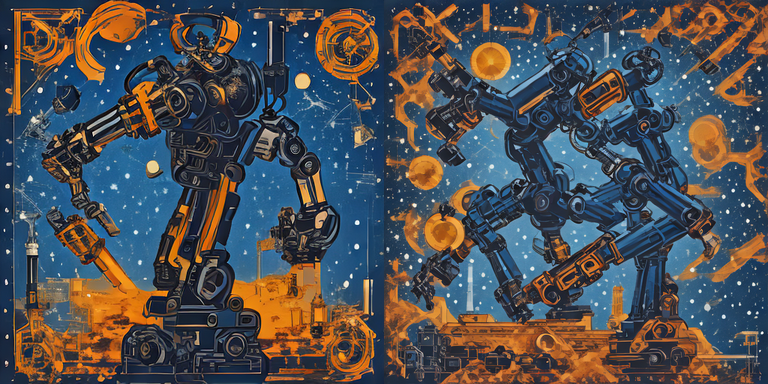

In [10]:
from IPython.display import display,Markdown
TOLS={'clip':1.,'edge':.10,'contrast':.10,'seconds':.20}
def classify_rows(rows):
    out=[]
    for metric,a,s,b,d,ratio,sig in rows:
        tolerance=TOLS[metric] if metric=='clip' else TOLS[metric]*abs(a)
        practical=bool(abs(d)>tolerance)
        direction=-d if metric=='seconds' else d
        label='нейтрально' if not practical else 'улучшение' if direction>0 else 'ухудшение'
        out.append(dict(metric=metric,A=a,s_A=s,B=b,delta=d,ratio=ratio,over_2s=sig,tolerance=tolerance,practical=practical,label=label,criteria_disagree=bool(sig)!=practical))
    return out
classified=classify_rows(result['rows'])
write_json(OUT/'classification.json',classified)
def table(rows):
    header='| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |\n|---|---:|---:|---:|---:|---:|---|---:|---|\n'
    return header+'\n'.join(f"| {r['metric']} | {r['A']:.6f} | {r['s_A']:.6f} | {r['B']:.6f} | {r['delta']:+.6f} | {r['ratio']:.3f} | {r['over_2s']} | {r['tolerance']:.6f} | {r['label']} |" for r in rows)
display(Markdown(table(classified)))
print('Расхождения критериев:',[r['metric'] for r in classified if r['criteria_disagree']])
normalized=[]
for r in records:
    img=Image.open(OUT/r['file']).convert('RGB').resize((512,512),Image.Resampling.LANCZOS)
    normalized.append(dict(condition=r['condition'],seed=r['seed'],edge=M.edge_energy(img),contrast=M.contrast(img)))
rows=[]
for metric in ['edge','contrast']:
    aa=np.array([r[metric] for r in normalized if r['condition']=='A']);bb=np.array([r[metric] for r in normalized if r['condition']=='B'])
    d=float(bb.mean()-aa.mean());s=float(aa.std(ddof=1))
    rows.append((metric,float(aa.mean()),s,float(bb.mean()),d,abs(d)/s if s else float('inf'),bool(abs(d)>2*s)))
norm_class=classify_rows(rows)
write_json(OUT/'normalized_512.json',dict(records=normalized,classification=norm_class))
display(Markdown('### Общий масштаб 512×512\n'+table(norm_class)))
pair=[Image.open(OUT/f'{cond}_101/result.png').convert('RGB').resize((384,384),Image.Resampling.LANCZOS) for cond in ['A','B']]
sheet=Image.new('RGB',(768,384));sheet.paste(pair[0],(0,0));sheet.paste(pair[1],(384,0));sheet.save(OUT/'comparison.png')
print('Seed 101: A 512 слева; B 768 справа; одинаковый размер показа, оригиналы сохранены.')
display(sheet)

## 5. Намеренная ошибка: guidance=1

Проверяем на своём брифе и seed 101, сохраняем изображения. Симптом — ожидать включения CFG при 1; диагностика — SHA-256 и pipe.do_classifier_free_guidance после каждого вызова. При 3 CFG активен, но это исследование за пределами рекомендованного режима SD-Turbo.

In [11]:
guidance=[];gimgs=[]
for value in [0.,1.,3.]:
    img=L.generate(pipe,L.BRIEFS[c],101,guidance=value)[0]
    payload=L.png_bytes(img);name=f'guidance_{int(value)}.png';(OUT/name).write_bytes(payload)
    guidance.append(dict(guidance=value,cfg_active=bool(pipe.do_classifier_free_guidance),sha256=L.sha(payload),file=name));gimgs.append(img)
error_check=dict(records=guidance,equal_0_1=guidance[0]['sha256']==guidance[1]['sha256'],psnr_0_3=L.psnr_db(gimgs[0],gimgs[2]))
assert error_check['equal_0_1'] and [r['cfg_active'] for r in guidance]==[False,False,True]
write_json(OUT/'guidance_check.json',error_check);print(json.dumps(error_check,indent=2))

{
  "records": [
    {
      "guidance": 0.0,
      "cfg_active": false,
      "sha256": "84db2534b3e66ea6f5ac17a7d3ba210bfb7653bcd738534372564a5b46b79b36",
      "file": "guidance_0.png"
    },
    {
      "guidance": 1.0,
      "cfg_active": false,
      "sha256": "84db2534b3e66ea6f5ac17a7d3ba210bfb7653bcd738534372564a5b46b79b36",
      "file": "guidance_1.png"
    },
    {
      "guidance": 3.0,
      "cfg_active": true,
      "sha256": "b961e528cd31aa9da0ce4a7aeb68cbca550ddd3f993f5cd301260ed739e8c015",
      "file": "guidance_3.png"
    }
  ],
  "equal_0_1": true,
  "psnr_0_3": 11.605078740312596
}


## 6. Итоговый анализ и контрольные вопросы

# Итоговый вывод

В данной серии увеличение размера с 512 до 768 не дало практической пользы по выбранным допускам. Время выросло на 112,1% (0,3453 → 0,7324 с), что превышает и 20% допуска, и 2s_A. CLIP снизился на 1,6127 пункта (30,7979 → 29,1852): по допуску ±1 это ухудшение, но |Δ|/s_A=1,127 и критерий 2s не выполнен. Это реальное расхождение критериев; формальная статистическая значимость не заявляется.

Энергия границ снизилась на 6,0%, контраст на 6,4%; оба отклика нейтральны по ±10% и не выходят за 2s. При общем масштабе 512 энергия границ, наоборот, выросла на 8,0%, а контраст снизился на 8,3% — оба изменения также в пределах допуска. Смена знака градиентной метрики показывает зависимость от масштаба и не даёт основания объявлять изображение качественнее.

На сравнительном листе для seed 101 режим 768 даёт пересечения и дублирование механических частей; отдельная механическая рука не стала более узнаваемым главным объектом. Для данного брифа и пяти seed сохраняем рекомендуемый размер 512. Проверка guidance подтвердила совпадение 0/1 при CFG=False; при 3 CFG=True, результат отличается. Выводы ограничены одной моделью, GPU и сеансом, пятью seed и выбранными метриками; время особенно зависит от состояния среды. Независимая локальная проверка пересчитывает SHA-256, пространственные метрики и статистику, но не пересчитывает CLIP-эмбеддинги.


# Визуальная оценка seed 101

A (512×512): тёмный человекоподобный робот занимает центр, механические руки и шарниры читаются; янтарные детали контрастируют с синим фоном. Вместо отдельного силуэта руки модель создала почти целую фигуру робота. Поэтому соответствие брифу частичное уже в базовом режиме.

B (768×768): композиция раздроблена, видны несколько пересекающихся и повторяющихся механических конечностей и шарниров; центральный единичный силуэт читается хуже. Часть деталей уходит за края кадра. Синяя и янтарная палитра сохранена. При одинаковом размере показа заметно, что дополнительные пиксели не дали более ясной формы механической руки. На обоих изображениях не обнаружено явного читаемого текста или узнаваемого логотипа.

Наблюдение: у B для seed 101 есть признаки дублирования частей, характерные для выхода за рекомендованный размер. Объяснение как возможный эффект размера согласуется с изменением единственного параметра, однако эта пара не доказывает универсальный механизм артефактов. При изменении формы тензора один seed не означает одинаковый начальный шум. Вывод относится к этой серии, модели и версии конвейера. Изображения являются художественными концептами, а не чертежами реальной техники.


# Ответы на контрольные вопросы ЛР6

1. Один фактор меняют для отделения его эффекта от других причин. Серия seed 101–105 показывает вариабельность результатов, которую одна удачная картинка не отражает.

2. |Δ|>2s_A показывает, превышает ли среднее изменение удвоенный разброс A между seed; это учебная эвристика, не формальный тест и не мера пользы. В нашей серии CLIP: |Δ|=1,6127>1,0 практического допуска, но <2s_A=2,8618. Практически хуже, по 2s эффект не выделяется.

3. Сходство CLIP - косинус между эмбеддингами картинки и текста ×100, здесь ViT-B/32. Английский бриф фиксирует единую цель оценки и уменьшает влияние слабой работы кодировщика с русским. Это не эстетическая оценка и не CLIPScore.

4. Энергия границ растёт также от шума, раздробленной композиции и повторяющихся деталей. В нашем контроле одинакового масштаба знак изменения границ поменялся, а визуальная ясность B не стала лучше; рост показателя не равен росту качества.

5. В этом Diffusers-конвейере CFG включается при scale>1. При 0 и 1 получили одинаковые SHA-256 и пиксели, CFG=False; при 3 CFG=True и PSNR относительно 0 равен 11,6051 дБ. Исправление - проверять статус CFG, не ожидать эффекта от 1; для SD-Turbo базовый режим 0.

6. 768 выходит за рекомендованный размер 512: могут появляться повторы и неверная композиция. В B для seed 101 заметны несколько пересекающихся конечностей и размытая центральная структура; A более цельное. Оба изображения соответствуют требованию об отдельной механической руке только частично.

7. (0,55−0,30)/0,30×100%=83,33%. Это ухудшение времени по допуску 20%. Для нашей фактической серии рост составляет 112,10%.

8. Если оценивать русский вариант относительно русского текста, одновременно меняются изображение и измерительная цель, а языковая слабость CLIP смешивается с качеством генерации. Один английский бриф оставляет цель одинаковой для обоих режимов.

9. До запуска приняты допуски методички: CLIP ±1 пункт, границы/контраст ±10% A, время ±20% A. При удвоении допусков CLIP станет нейтральным (1,6127<2), время останется ухудшением (112,1%>40%), границы и контраст останутся нейтральными. Критерий 2s от допуска не зависит. Порог нельзя менять задним числом для желаемого вывода.

10. Нужны ID и ревизии SD-Turbo и CLIP, исходные скрипты, prompt и общий текст оценки, seed, размеры, шаги, guidance, dtype и устройство генератора, GPU/драйвер и версии, прогрев и порядок вызовов, определение метрик, ddof=1 и допуски. Время может отличаться даже при соблюдении паспорта; новый сеанс отдельно не проверялся.


## Источники и вклад

Исходники преподавателя сохранены без изменения, их SHA-256 проверены. Индивидуальный вклад: гипотеза, допуски, сохранение серии, контроль масштаба, независимый пересчёт и визуальный анализ. Источники: приложенная PDF-методичка ЛР6; [WorkspaceArray](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html); [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo/tree/b261bac6fd2cf515557d5d0707481eafa0485ec2), [лицензия закреплённой ревизии](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/LICENSE.md); [CLIP ViT-B/32](https://huggingface.co/openai/clip-vit-base-patch32/tree/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268). Синтетический учебный запуск; открытость весов не отменяет их лицензионных условий.

Пояснения к фактическим результатам добавлены после скачивания выполненного ноутбука. Код и результаты ячеек сохранены без изменения.


In [12]:
lines=['# Численный вывод варианта 3',table(classified),'\nРасхождения 2s и допуска: '+str([r['metric'] for r in classified if r['criteria_disagree']]),'\nРост показателей границ/контраста не равен росту художественного качества.']
(OUT/'conclusion.md').write_text('\n\n'.join(lines));display(Markdown('\n\n'.join(lines)))
import importlib.metadata as metadata
packages={name:metadata.version(name) for name in ['torch','diffusers','transformers','accelerate','safetensors','huggingface_hub','numpy','scipy','Pillow']}
passport=dict(student='Власюк Данил Витальевич',group='Т26ИИКТ-МИК11',variant=N,started_utc=STARTED,finished_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),model_id=L.MODEL_ID,revision=L.REVISION,clip_id=M.CLIP_ID,clip_revision=M.CLIP_REVISION,gpu=GPU,python=sys.version,platform=platform.platform(),packages=packages,seeds=list(M.SEEDS),settings_A=a_cfg,settings_B=b_cfg,generator='cpu; fresh generator each call',dtype=str(pipe.unet.dtype),tolerances=TOLS,source_sha256=EXPECTED,independent_new_session_tested=False)
write_json(OUT/'passport.json',passport)
(OUT/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
archive=shutil.make_archive('/content/LR06_variant3_results','zip',OUT)
print('COMPLETE; ARCHIVE',archive)
from google.colab import files
files.download(archive)

# Численный вывод варианта 3

| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |
|---|---:|---:|---:|---:|---:|---|---:|---|
| clip | 30.797867 | 1.430902 | 29.185187 | -1.612680 | 1.127 | False | 1.000000 | ухудшение |
| edge | 0.045661 | 0.006960 | 0.042912 | -0.002749 | 0.395 | False | 0.004566 | нейтрально |
| contrast | 0.192287 | 0.022494 | 0.179979 | -0.012308 | 0.547 | False | 0.019229 | нейтрально |
| seconds | 0.345293 | 0.053011 | 0.732370 | +0.387077 | 7.302 | True | 0.069059 | ухудшение |


Расхождения 2s и допуска: ['clip']


Рост показателей границ/контраста не равен росту художественного качества.

COMPLETE; ARCHIVE /content/LR06_variant3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>